
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Sistema de recomendaciones

El siguiente texto ofrece una definición de **sistema de recomendaciones** :


* ¿Qué es?

> Un sistema de recomendaciones es un tipo de software que utiliza **algoritmos** para analizar los datos de un usuario y proporcionar sugerencias personalizadas sobre productos, servicios o contenidos que puedan ser de su interés.

* ¿En base a qué se desarrollan?

> Estos sistemas de recomendación se basan en el análisis de patrones en los datos de usuarios, como el historial de compras, la navegación en la web o la información de perfil, para determinar qué productos o servicios podrían ser relevantes para ellos. El sistema utiliza estos datos para hacer recomendaciones personalizadas a los usuarios, con el objetivo de mejorar su experiencia y aumentar su fidelidad a una marca o sitio web.

* ¿Para qué se utilizan?

> Los sistemas de recomendación se utilizan ampliamente en aplicaciones de comercio electrónico, redes sociales, sitios de streaming de video y música, y muchas otras plataformas en línea. Algunos ejemplos populares de sistemas de recomendación son el algoritmo de recomendaciones de Netflix, el motor de recomendación de Amazon y el algoritmo de recomendación de YouTube.


Podemos aplicar varias estrategias para implementar un sistema de recomendaciones, una de ellas es el análisis de la canasta de compras (**market basket analysis**), otra estrategia es el **filtrado colaborativo**, estrategia que exploraremos en esta libreta.  

# Filtrado colaborativo

En este documento exploraremos la técnica de **filtrado colaborativo** con el objetivo de construir sistemas de recomendación.

La implementación del filtrado colaborativo requiere de una estructura de datos denominada matriz **cliente-producto**:

\begin{matrix}
  \hline
  \text{Cliente/producto} & p_1 & p_2 & \cdots & p_m \\
  \hline
  c_1 & w_{11} & w_{12} & \cdots & w_{1_m} \\
  c_2 & w_{21} & w_{12} & \cdots & w_{2_m} \\
  \vdots & \vdots & \vdots & \cdots & \vdots \\
  c_n & w_{n1} & w_{n2} & \cdots & w_{nm} \\
  \hline
\end{matrix}

En esta matriz, los pesos, $w_{ij}$, **indican** de alguna manera **la preferencia** que tiene el cliente i-ésimo, por el producto j-ésimo, por ejemplo:

* $w_{ij}$ puede ser una **calificación** que el cliente asigna de forma explícita a un producto.
* $w_{ij}$ puede ser un valor binario que indica si el cliente ha **adquirido** el producto correspondiente.



## Matriz dispersa

Considera que la mayoría de las celdas de la matriz cliente-producto tienen **valores desconocidos**, dado que los catálogos de productos suelen ser amplios, y resulta impráctico solicitar a los clientes que los evalúen.

Podemos sin embargo, hacer recomendaciones a un cliente basándonos en dos enfoques:

1. **Basado en clientes (usuarios)**: identificamos a otros clientes con características similares al primero y le recomendamos los productos por los que esos otros clientes tienen preferencia, o han sido adquiridos por ellos pero no por el primer cliente.
2. **Basado en el producto**: identificamos productos por los que el cliente tiene preferencia, o ha sido adquiridos por el cliente, y le recomendamos productos similares.


# Ejemplo

## Acceso a datos

Descargar los datos del enlace:

http://archive.ics.uci.edu/ml/datasets/online+retail#

In [ ]:
df = pd.read_excel(io='Online Retail.xlsx', sheet_name='Online Retail')
df.head()

BadZipFile: File is not a zip file

In [ ]:
df.shape

(541909, 8)

## Limpieza


* **Una buena cantidad de clientes no están identificados**:

In [ ]:
df.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Eliminamos observaciones en las que no se puede identificar al cliente/usuario:

In [ ]:
df[df['CustomerID'].isna()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
541536,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09 10:26:00,4.13,NaN,United Kingdom
541537,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09 10:26:00,4.13,NaN,United Kingdom
541538,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09 10:26:00,4.96,NaN,United Kingdom
541539,581498,85174,S/4 CACTI CANDLES,1,2011-12-09 10:26:00,10.79,NaN,United Kingdom


In [ ]:
df = df[~df['CustomerID'].isna()]
df.shape

(406829, 8)

Aseguramos que identificamos a todos los usuarios:

In [ ]:
df['CustomerID'].isna().sum()

np.int64(0)

* **El conjunto tiene datos inválidos y atípicos**:

<Axes: >

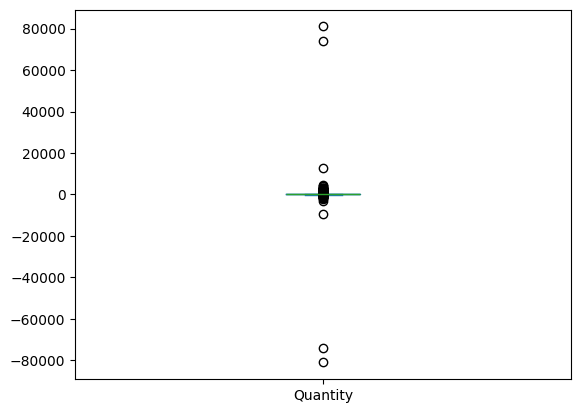

In [ ]:
df['Quantity'].plot.box()

Filtramos observaciones válidas (y eliminamos algunos datos atípicos):

In [ ]:
df = df[(np.abs(df['Quantity']) < 10000) & (df['Quantity']>0)]
df.shape

(397921, 8)

<Axes: >

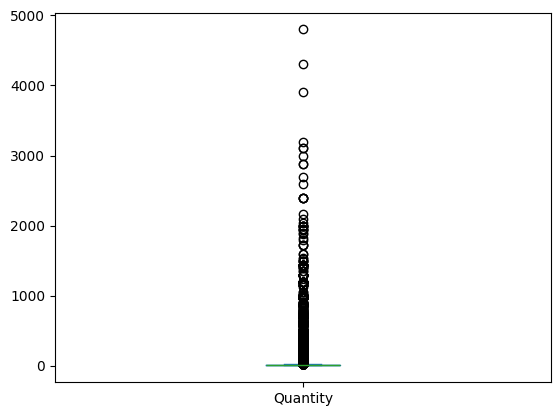

In [ ]:
df['Quantity'].plot.box()

## Matriz cliente-ítem

In [ ]:
cliente_item = df.pivot_table(
    index='CustomerID', #clientes a las filas
    columns='StockCode', #productos a las columnas
    values='Quantity',
    aggfunc='sum'
)
cliente_item.head()

StockCode,10002,10080,10120,10125,10133,10135,11001,15030,15034,15036,...,90214V,90214W,90214Y,90214Z,BANK CHARGES,C2,DOT,M,PADS,POST
CustomerID,,,,,,,,,,,,,,,,,,,,,
12347.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12348.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0
12349.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
12350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
12352.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,7.0


La matriz contiene 4337 filas (clientes) y 3664 columnas (productos)

In [ ]:
cliente_item.shape

(4337, 3664)

Considerando que los pesos de la matriz indican cuántas unidades ha adquirido cada cliente de cada producto, interpretamos que los ```na```'s corresponden a ceros. Transformamos la matriz para que las celdas indiquen si el cliente ha adquirido el producto corresondiente.

In [ ]:
cliente_item = cliente_item.map(lambda x: 1 if x > 0 else 0)
cliente_item.head()

StockCode,10002,10080,10120,10125,10133,10135,11001,15030,15034,15036,...,90214V,90214W,90214Y,90214Z,BANK CHARGES,C2,DOT,M,PADS,POST
CustomerID,,,,,,,,,,,,,,,,,,,,,
12347.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12348.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
12349.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
12350.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
12352.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1


**Mapa de calor**

Visualizamos mejor la matriz mediante un mapa de calor.

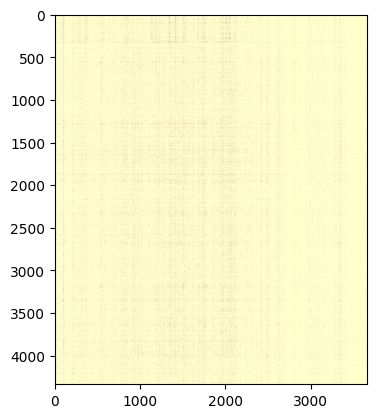

In [ ]:
plt.imshow(cliente_item, cmap="YlOrRd")
plt.show()

En promedio, cada cliente ha adquirido 61 productos diferentes.

In [ ]:
cliente_item.sum(axis=1).mean()

np.float64(61.51694719852433)

**¿Cómo cuantificamos la similitud entre clientes?**

Cada cliente está representado por un vector, de valores binarios, que indica cuáles productos ha adquirido:

In [ ]:
cliente_item.loc[14911.0][:30]

,14911.0
StockCode,
10002,1
10080,0
10120,0
10125,0
10133,1
10135,1
11001,1
15030,0
15034,0


In [ ]:
cliente_item.loc[14913.0][:30]

,14913.0
StockCode,
10002,0
10080,0
10120,0
10125,0
10133,1
10135,1
11001,0
15030,0
15034,0


Dado que cada cliente se representa con un vector, evaluar la similitud entre clientes equivale a evaluar similitud entre vectores.

## Similitud coseno

Evaluamos la similitud de dos vectores/clientes diferentes a partir de la similitud coseno:

$$\text{cosine}(A, B) = \frac{A\cdot B}{|A|\times |B|}$$

Cuando las componentes de los vectores son todas positivoas, como el caso que revisamos, los valores de la similitud coseno están acotados al intervalo $[0, 1]$ siendo el cero la mínima similitud y 1 la máxima.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
sim_matrix = pd.DataFrame(cosine_similarity(cliente_item), columns=cliente_item.index, index=cliente_item.index)
sim_matrix

CustomerID,12347.0,12348.0,12349.0,12350.0,12352.0,12353.0,12354.0,12355.0,12356.0,12357.0,...,18273.0,18274.0,18276.0,18277.0,18278.0,18280.0,18281.0,18282.0,18283.0,18287.0
CustomerID,,,,,,,,,,,,,,,,,,,,,
12347.0,1.000000,0.063022,0.046130,0.047795,0.038484,0.0,0.025876,0.136641,0.094742,0.060262,...,0.0,0.029709,0.052668,0.000000,0.032844,0.062318,0.000000,0.113776,0.109364,0.012828
12348.0,0.063022,1.000000,0.024953,0.051709,0.027756,0.0,0.027995,0.118262,0.146427,0.000000,...,0.0,0.064282,0.113961,0.000000,0.000000,0.000000,0.000000,0.000000,0.170905,0.083269
12349.0,0.046130,0.024953,1.000000,0.056773,0.137137,0.0,0.030737,0.032461,0.144692,0.153389,...,0.0,0.105868,0.000000,0.000000,0.039014,0.000000,0.000000,0.067574,0.137124,0.030475
12350.0,0.047795,0.051709,0.056773,1.000000,0.031575,0.0,0.000000,0.000000,0.033315,0.021190,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.044866,0.000000
12352.0,0.038484,0.027756,0.137137,0.031575,1.000000,0.0,0.102568,0.036108,0.089414,0.068248,...,0.0,0.157014,0.000000,0.000000,0.000000,0.000000,0.000000,0.037582,0.080278,0.033898
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18280.0,0.062318,0.000000,0.000000,0.000000,0.000000,0.0,0.041523,0.000000,0.000000,0.055258,...,0.0,0.000000,0.000000,0.000000,0.105409,1.000000,0.119523,0.000000,0.000000,0.000000
18281.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.049629,0.000000,0.000000,0.066046,...,0.0,0.000000,0.000000,0.000000,0.000000,0.119523,1.000000,0.000000,0.046613,0.000000
18282.0,0.113776,0.000000,0.067574,0.000000,0.037582,0.0,0.000000,0.160128,0.079305,0.025222,...,0.0,0.174078,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.017800,0.000000


Identifiquemos los usuarios con mayor similitud a algún usuario en particular:

In [ ]:
A = 17935.0 #consideremos al usuario 17935.0

sim_matrix.loc[A].sort_values(ascending=False).iloc[:10]

,17935.0
CustomerID,
17935.0,1.000000
14813.0,0.264575
12650.0,0.211289
16305.0,0.201456
18174.0,0.188982
18017.0,0.188982
12616.0,0.188982
16953.0,0.188982
17029.0,0.188982


¿Qué artículos ha adquirido el cliente con mayor similitud?

In [ ]:
B = 14813.0
items_B = cliente_item.loc[B]
items_B = items_B[items_B>0]
items_B

,14813.0
StockCode,
20828,1
21034,1
21955,1
21982,1
22449,1
22450,1
22451,1
22585,1
22632,1


In [ ]:
s_b = set(items_B.index)
s_b

{'17091J',
 20828,
 21034,
 21955,
 21982,
 22449,
 22450,
 22451,
 22585,
 22632,
 22633,
 22654,
 22752,
 22753,
 22754,
 22755,
 22758,
 22834,
 22837,
 22865,
 22866,
 22867,
 '72349B',
 '84508B',
 '85124C'}

¿Qué recomendamos al cliente A?

In [ ]:
# productos que ha adquirido el cliente A
items_A = cliente_item.loc[A]
items_A = items_A[items_A>0]
s_a=set(items_A.index)
s_a

{20657,
 20659,
 20828,
 20856,
 21051,
 21866,
 21867,
 22208,
 22209,
 22210,
 22211,
 22449,
 22450,
 22551,
 22553,
 22557,
 22640,
 22659,
 22749,
 22752,
 22753,
 22754,
 22755,
 23290,
 23292,
 23309,
 '85099B',
 'POST'}

Recomendamos los productos que ha adquirido el cliente B pero que no han sido adquiridos por el cliente A:

In [ ]:
s_b-s_a

{'17091J',
 21034,
 21955,
 21982,
 22451,
 22585,
 22632,
 22633,
 22654,
 22758,
 22834,
 22837,
 22865,
 22866,
 22867,
 '72349B',
 '84508B',
 '85124C'}

In [ ]:
s_a.intersection(s_b) # productos que han adquirido ambos clientes

{20828, 22449, 22450, 22752, 22753, 22754, 22755}